In [1]:
import numpy as np
import picos as pc
from math import comb
from itertools import combinations
import mosek
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from wolframclient.evaluation import WolframLanguageSession
from wolframclient.language import wl, wlexpr

import datetime
import time
import os

/usr/lib/python3.14/importlib/__init__.py:88: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _bootstrap._gcd_import(name[level:], package, level)


In [2]:
NOTEBOOK_PATH =  os.getcwd()

on_Windows = False
if "\\" in NOTEBOOK_PATH:
    on_Windows = True
    NOTEBOOK_PATH = NOTEBOOK_PATH.replace("\\", "/") #replace backslashes on windows


#<<<<<<<<<<WolframKernel Path<<<<<<<<<<<<<<<
#windows
if on_Windows: 
    WOLFRAMKERNEL_PATH = r"C:\Program Files\Wolfram Research\Wolfram Engine\15.0\WolframKernel.exe" 

else: 
    #Linux
    WOLFRAMKERNEL_PATH = "/usr/bin/WolframKernel"
#<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<<

#<<<<<<<<<<<Mosek license <<<<<<<<<<<<<<<<<<
if on_Windows: 
    %env MOSEKLM_LICENSE_FILE=C:\Users\jonat\Documents\.mosek
else:
    %env MOSEKLM_LICENSE_FILE=/home/jnat/.mosek/mosek.lic


env: MOSEKLM_LICENSE_FILE=/home/jnat/.mosek/mosek.lic


In [3]:
pc.available_solvers()

['cvxopt', 'mosek', 'mskfsn']

In [4]:
ATOL = 1E-8

# Partial trace function and extensions SDP

In [5]:
def is_herm(matrix: np.ndarray) -> bool:
    """Check whether `matrix` is Hermitian."""
    
    return np.allclose(matrix, matrix.conj().T)


def is_psd(matrix: np.ndarray) -> bool:
    """Test `matrix` for positive semi-definiteness."""

    if is_herm(matrix):
        return np.all(np.linalg.eigvalsh(matrix) >= - ATOL)
    else:
        return False

def is_measurement(meas: list[np.ndarray]) -> bool:
    """Check whether `meas` is a well-defined quantum measurement.

    Args:
        meas (list): list of ndarrays representing the measurement's effects.

    Returns:
        bool: returns `True` iff `meas` is composed of effects which are:
            - Square matrices with the same dimension,
            - Positive semi-definite, and
            - Sum to the identity operator.
    """

    dims = meas[0].shape

    try:
        square = len(dims) == 2 and dims[0] == dims[1]
        same_dim = np.all(np.asarray([eff.shape for eff in meas]) == dims)
        psd = np.all([is_psd(eff) for eff in meas])
        complete = np.allclose(sum(meas), np.eye(dims[0]))
    except (ValueError, np.linalg.LinAlgError):
        return False

    return square and same_dim and psd and complete

In [6]:
def rank(c):
    """
    Computes the rank of a combinations (c0, ..., ck) in the combinatorial number system.
    """
    rank = 0
    for i, c_i in enumerate(c): 
        rank += comb(c_i, i+1)
    return rank
    
def get_Eij(i, j, dim):
    """
    Matrix with 1 at index i, j and zero everywhere else. 
    """
    M = np.zeros((dim, dim))
    M[i][j] = 1
    return M

In [7]:
def sym_partial_trace(A: pc.HermitianVariable, dim: int, k: int):
    """Computes the partial trace of A over symmetric subspace.

    Args:
        A (pc.HermitianVariable): Hermitian Operator on symmetric subspace.
        d (int): dimension of the underlying Hilbert Space.
        k (int): number of marginal systems

    Returns: 
        (pc.HermitianVariable): (d x d)-matrix that represents the partial trace of A. 
    """
    total_pos = k+dim-1
    terms = []
    E = [[get_Eij(l, k, dim) for k in range(dim)] for l in range(dim)]
    for c in combinations(range(total_pos), dim-1):
        
        ds = rank(c) #dicke state index
        A_ds = A[ds,ds]
        w = [c[0]] + [c[n]-c[n-1]-1 for n in range(1, dim-1)] + [total_pos-1-c[dim-2]] #notice + is append here
        for i in range(0, dim):
            terms.append(w[i] * A_ds * E[i][i])
            for j in range(1+i, dim):                         
                #the terms where w[i] = 0 are zero but we have to explicitly check, otherwise
                #we get an indexing error for A[ds, ds_lshift]
                if w[i] > 0: 
                    c_lshift = np.array(c)
                    c_lshift[i:j] -= 1
                    ds_lshift = rank(c_lshift)
                    terms.append(np.sqrt(w[i]*(w[j]+1)) * A[ds, ds_lshift] * E[i][j])
                if w[j] > 0:
                    c_rshift = np.array(c)
                    c_rshift[i:j] += 1
                    ds_rshift = rank(c_rshift)
                    terms.append(np.sqrt(w[j]*(w[i]+1)) * A[ds, ds_rshift] * E[j][i])
    return pc.sum(terms) / k #pc.sum produces a weird string, sum(terms) is more readable

In [8]:
def get_extensionSDP(meas: list[np.ndarray], k: int):
    """
    Args:
        meas (list): list of ndarrays represetening the measurement's effects.
        k (int): level of the extension
    Returns:
        SDP (pc.Problem): SDP for finding the amount of noise need for meas to have a 
        Bose-Symmetric extension to level k. 
    """
    assert(is_measurement(meas))

    dim = meas[0].shape[0] #dimension of the Hilbert space
    dim_sym = comb(k + dim - 1, dim - 1) #dimension of symmetric subspace Sym(H, k)
    n_a = len(meas) #number of effects

    SDP = pc.Problem()

    # Constants
    noise_effect = pc.Constant("noise_effect", np.eye(dim) / dim)
    sym_proj = pc.Constant("sym_proj", dim * np.eye(dim_sym) / dim_sym)
    M = [pc.Constant(f"M_{a}", meas[a]) for a in range(n_a)]

    # Variables
    eta = pc.RealVariable("eta", 1)
    SDP.add_constraint(eta <= 1)

    N = [pc.HermitianVariable(f"N_{a}", dim_sym) for a in range(n_a)]
    ptrN = []

    SDP.add_list_of_constraints([n >> 0 for n in N])
    SDP.add_constraint(pc.sum([n for n in N]) == sym_proj)

    for a in range(n_a):
        SDP.add_constraint( eta * M[a] + (1-eta) * pc.trace(M[a]) * noise_effect == sym_partial_trace(N[a],dim, k))
    SDP.set_objective("max", eta)

    return SDP

# Qubits

### Defining some unbiased qubit measurements

In [9]:
"""
Qubit POVMs: projective, trine, SIC, and the general unbiased four-outcome
family.

Every POVM built here is *unbiased*: all of its effects share the same
trace, 2/N for N outcomes. Every unbiased qubit POVM effect can be written in
Bloch form as

    E_k = (1/N) * (I + r_k . sigma)

for a set of Bloch vectors {r_k}, where N is the number of outcomes. This
is valid whenever sum_k r_k = 0 (completeness) and |r_k| <= 1 for every k
(positivity); |r_k| = 1 gives a rank-one (extremal) effect. This module
implements that map once, in `bloch_vectors_to_povm`, and builds every
other measurement on top of it.

References
----------
The two-parameter family for unbiased extremal four-outcome qubit POVMs
(eq. 23) is taken from:
    F. Curran, "Quantum randomness beyond projective measurements",
    arXiv:2605.18291 (2026), Section 5.1.
"""

import numpy as np

# Pauli matrices
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)


def bloch_vectors_to_povm(bloch_vectors):
    """
    Convert a list/array of Bloch vectors into the effects of the unbiased
    qubit POVM they define:

        E_k = (1/N) * (I + r_k . sigma),   N = number of vectors

    Valid whenever sum_k r_k = 0 (completeness, checked in `verify_povm`)
    and |r_k| <= 1 for every k (positivity). |r_k| == 1 gives a rank-one
    (extremal) effect.
    """
    bloch_vectors = np.asarray(bloch_vectors, dtype=float)
    N = len(bloch_vectors)
    effects = []
    for r in bloch_vectors:
        E = (1.0 / N) * (I2 + r[0] * X + r[1] * Y + r[2] * Z)
        effects.append(E)
    return effects

# ---------------------------------------------------------------------------
# 1. Arbitrary projective measurement (2 outcomes)
# ---------------------------------------------------------------------------

def projective_measurement(theta, phi):
    """
    Arbitrary rank-one projective qubit measurement, {E_+, E_-}.

    theta, phi : polar / azimuthal angles (radians) of the measurement
    axis n = (sin(theta)cos(phi), sin(theta)sin(phi), cos(theta)) on the
    Bloch sphere. Any qubit projective measurement is of this form.
    """
    n = np.array([
        np.sin(theta) * np.cos(phi),
        np.sin(theta) * np.sin(phi),
        np.cos(theta),
    ])
    return bloch_vectors_to_povm([n, -n])


# ---------------------------------------------------------------------------
# 2. Trine POVM (3 outcomes)
# ---------------------------------------------------------------------------

def trine_povm():
    """
    The trine measurement: the unique unbiased extremal 3-outcome qubit
    POVM, with Bloch vectors equally spaced (120 degrees apart) in a
    plane through the origin.
    """
    angles = [0.0, 2 * np.pi / 3, 4 * np.pi / 3]
    vectors = [np.array([np.sin(t), 0.0, np.cos(t)]) for t in angles]
    return bloch_vectors_to_povm(vectors)


# ---------------------------------------------------------------------------
# 4. General unbiased extremal 4-outcome POVM (2-parameter family)
# ---------------------------------------------------------------------------

def unbiased_four_outcome_povm(delta, alpha):
    """
    The general unbiased extremal 4-outcome qubit POVM, parameterized by
    two angles (delta, alpha) -- eq. (23) of arXiv:2605.18291. Up to a
    global rotation, EVERY unbiased extremal 4-outcome qubit POVM has
    this form; the vectors {r_j} are the vertices of a disphenoid (a
    tetrahedron with four congruent triangular faces).

    Parameters
    ----------
    delta : float, 0 < delta < pi/2
    alpha : float, -pi/2 < alpha < pi/2
        alpha = 0 and delta = arccos(1/sqrt(3)) recovers the SIC POVM.
        alpha = 0 alone gives the one-parameter 'scissors' family.
    """
    if not (0 < delta < np.pi / 2):
        raise ValueError("delta must be in (0, pi/2)")
    if not (-np.pi / 2 < alpha < np.pi / 2):
        raise ValueError("alpha must be in (-pi/2, pi/2)")

    cd, sd = np.cos(delta), np.sin(delta)
    ca, sa = np.cos(alpha), np.sin(alpha)

    r1 = np.array([-cd, -sd, 0.0])
    r2 = np.array([-cd, sd, 0.0])
    r3 = np.array([cd, -sd * sa, sd * ca])
    r4 = np.array([cd, sd * sa, -sd * ca])

    return bloch_vectors_to_povm([r1, r2, r3, r4])


# ---------------------------------------------------------------------------
# 3. SIC-POVM (4 outcomes) -- special case of the family above
# ---------------------------------------------------------------------------

def sic_povm():
    """
    The (tetrahedral) qubit SIC-POVM: the symmetric informationally
    complete 4-outcome POVM, whose Bloch vectors point to the vertices of
    a regular tetrahedron. Obtained from `unbiased_four_outcome_povm`
    with alpha = 0, delta = arccos(1/sqrt(3)), as noted below eq. (23) of
    arXiv:2605.18291.
    """
    delta = np.arccos(1.0 / np.sqrt(3.0))
    return unbiased_four_outcome_povm(delta, alpha=0.0)

### Iterating over unbiased qubit measurements and plotting a heat map of incompatibility

In [10]:
N = 40 #number of delta / alpha values. N^2 total measurements
k = 15 #extension level

delta_array = np.linspace(0 + 1/N, np.pi/2 - 1/N, N)
alpha_array = np.linspace(-np.pi/2 + 1/N, np.pi/2 - 1/N, N)

In [11]:
#generating data
if False:
    eta_array = np.empty([N,N]) 
    t_array = np.empty([N,N])
    
    for i, delta in enumerate(delta_array):
        for j, alpha in enumerate(alpha_array):
            meas = unbiased_four_outcome_povm(delta, alpha)
            SDP = get_extensionSDP(meas, k)
            start_time = time.time()
            SDP.solve(solver="mosek", verbosity=0)
            end_time = time.time()
                
            
            eta = SDP.get_variable("eta").value 
            t = end_time - start_time
    
            eta_array[i][j] = eta    
            t_array[i][j] = t 
    #saving data
    path = NOTEBOOK_PATH + "/data/iterating_unbiased/"
    
    np.save(path + f"eta_array_(k={k}, N={N})", eta_array)
    np.save(path + f"t_array_(k={k}, N={N})", t_array)      

In [12]:
#loading data
path = NOTEBOOK_PATH + "/data/iterating_unbiased/"

eta_array = np.load(path + f"eta_array_(k={k}, N={N})" + ".npy")
t_array = np.load(path + f"t_array_(k={k}, N={N})" + ".npy")

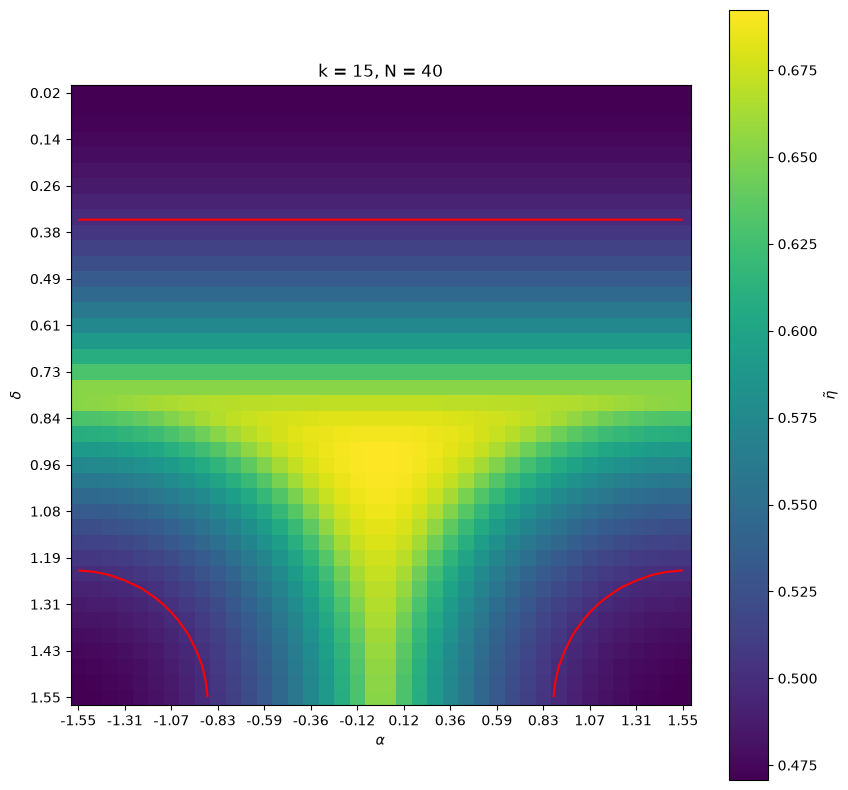

In [13]:
fig, ax = plt.subplots(figsize= (10, 10))

eta_tilde_array = eta_array * (k/(k+2))
im = ax.imshow(eta_tilde_array)


ticks_steps = 3
ax.set_xticks(range(N)[::ticks_steps], alpha_array.round(2)[::ticks_steps])
ax.set_yticks(range(N)[::ticks_steps], delta_array.round(2)[::ticks_steps])
ax.set_title(f"k = {k}, N = {N}")
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\delta$")

cbar = ax.figure.colorbar(im, ax=ax)
cbar.ax.set_ylabel(r"$\tilde\eta$")



PVM_bound = 0.5
ax.contour(eta_tilde_array, levels=[PVM_bound], colors='red')

#ax.contourf(eta_tilde_array, levels=[PVM_bound, eta_tilde_array.max()],
#            colors='none', hatches=['//'])

#ax.contourf(eta_tilde_array, levels=[PVM_bound, eta_tilde_array.max()], colors=['red'], alpha=0.2)

#mask = eta_tilde_array > PVM_bound
#overlay = np.where(mask, 1.0, np.nan)   # NaN -> fully transparent, so untouched pixels show the original colormap
#ax.imshow(overlay, cmap=ListedColormap(['red']), alpha=0.2, vmin=0, vmax=1)

#fig.savefig("heat_map.png")
plt.show()

### Looking at single measurements with increasing k

In [14]:
k_max = 30
k_array = np.arange(1, k_max+1)

#analytic solution for PVMs
def qubit_eta_PVM(k):
    if k % 2 != 0:
        return (k + 1)/(2*k)
    else: 
        return qubit_eta_PVM(k+1) 
qubit_eta_PVM = np.vectorize(qubit_eta_PVM)

In [15]:
#calculations
#SIC-POVM
if False:
    sic_meas = sic_povm()
    eta_sic_array = np.empty(k_max)
    t_sic_array = np.empty(k_max)
    
    #Trine-POVM
    trine_meas = trine_povm()
    eta_trine_array = np.empty(k_max)
    t_trine_array = np.empty(k_max)
    
    
    for i, k in enumerate(k_array):
        #SIC
        SDP = get_extensionSDP(sic_meas, k)
        start_time = time.time()
        SDP.solve(solver="mosek", verbosity=0)
        end_time = time.time()
            
        
        eta = SDP.get_variable("eta").value 
        t = end_time - start_time
    
        eta_sic_array[i] = eta
        t_sic_array[i] = t
    
        #trine
        SDP = get_extensionSDP(trine_meas, k)
        start_time = time.time()
        SDP.solve(solver="mosek", verbosity=0)
        end_time = time.time()
            
        
        eta = SDP.get_variable("eta").value 
        t = end_time - start_time
    
        eta_trine_array[i] = eta
        t_trine_array[i] = t
    #save data
    path = NOTEBOOK_PATH + "/data/single_POVMs/"
    
    #SIC
    np.save(path + f"eta_sic_array_(kmax={k_max})", eta_sic_array)
    np.save(path + f"t_sic_array_(kmax={k_max})", t_sic_array)
    
    #trine
    np.save(path + f"eta_trine_array_(kmax={k_max})", eta_trine_array)
    np.save(path + f"t_trine_array_(kmax={k_max})", t_trine_array)

In [16]:
#load data
path = NOTEBOOK_PATH + "/data/single_POVMs/"

#SIC
eta_sic_array = np.load(path + f"eta_sic_array_(kmax={k_max})" + ".npy")
t_sic_array = np.load(path + f"t_sic_array_(kmax={k_max})"+ ".npy")

#trine
eta_trine_array = np.load(path + f"eta_trine_array_(kmax={k_max})"+ ".npy")
t_trine_array = np.load(path + f"t_trine_array_(kmax={k_max})"+ ".npy")

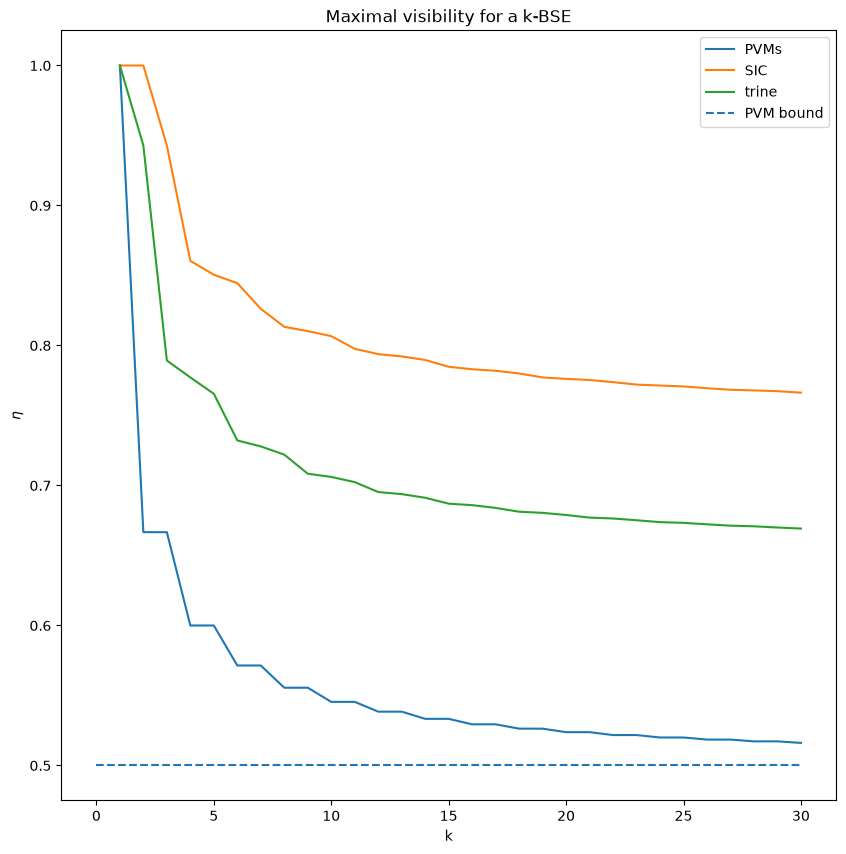

In [17]:
#plot
fig, ax = plt.subplots(figsize= (10, 10))

#PVMs
ax.plot(k_array, qubit_eta_PVM(k_array), label = "PVMs")

#SIC
ax.plot(k_array, eta_sic_array, label = "SIC")

#Trine
ax.plot(k_array, eta_trine_array, label = "trine")

#PVM bound
ax.hlines(0.5, 0, k_max, linestyles = "--", label = "PVM bound")



ax.set_xlabel("k")
ax.set_ylabel(r"$\eta$")

ax.set_title("Maximal visibility for a k-BSE")
ax.legend()

plt.show()

# Arbitrary dimension

### Sampling from random extremal POVMs

In [18]:
def get_extremals(s: int,hDim: int, oDim: int):
    """
    Samples extremal POVMs randomly. The methods will atmost produce s * (oDim-1) * hDim + 1 extremals. 
    See https://doi.org/10.1038/s41598-020-65934-w. 
    Args:
        s (int): number of non-extremal POVMs that are decomposed into the extremals. 
        hDim (int): Hilbert space dimension.
        oDim (int): Number of outcomes of the non-extremal POVM. 
    Returns: 
        povms (list[np.ndarray]): List of extremal POVMs.
    """

    
    SCRIPT_DIR = NOTEBOOK_PATH + "/Random-Sampling-Extremal-POVMs"
    SCRIPT = f"{SCRIPT_DIR}/GenerateExtremalPOVMs.wl"
    
    with WolframLanguageSession(WOLFRAMKERNEL_PATH) as session:
        # Make sure Needs["extremallibrary`"] and Needs["Quantum`"] can be found
        session.evaluate(wlexpr(f'SetDirectory["{SCRIPT_DIR}"]'))
    
        # Set parameters BEFORE running the script
        session.evaluate(wlexpr(f'Samplings = {s}; HilbertDim = {hDim}; Outcomedim = {oDim};'))
    
        # Run the script, then pull the result out of the kernel
        session.evaluate(wl.Get(SCRIPT))
        extremal_list = session.evaluate(wlexpr("N[Normal[extremalList]]"))
    
    #convert each extremal POVM to a numpy array
    POVMs = [np.array(e, dtype=complex) for e in extremal_list]

    return POVMs

In [19]:
#filter projectors out but keep one
def filter_pvms(POVMs):
    """
    Takes a list of POVMs and filters all PVMs, only keeping one PVM at index 0. 
    Args: 
        POVMs (list[np.ndarray]).

    Returns: 
        filtered_POVMs (list[np.ndarray]).
    """
    
    index_proj = [len(povm) == d for povm in POVMs]

    try:     
        first_proj_index = index_proj.index(True)
    except:
      print("There are no PVMs to be filtered.")
      return POVMs  

    proj = POVMs[first_proj_index]

    filtered_POVMs = []
    filtered_POVMs.append(proj)
    
    #put the projector in the first slot, fill the rest with non-projective POVMs
    filtered_POVMs[0] = proj
    for i, p in enumerate(POVMs):
        if not index_proj[i]:
            filtered_POVMs.append(p)

    return filtered_POVMs

In [20]:
#set parameters
d = 4
k = 2
oDim = 17
samples = 25

In [21]:
#calculations
if False:
    #get extremals
    t_start = time.time()
    POVMs = get_extremals(samples, d, oDim)
    POVMs = filter_pvms(POVMs)
    t_end = time.time()
    
    n_POVMs = len(POVMs)
    index_proj = [len(povm) == d for povm in POVMs]
    n_proj = sum(index_proj)
    print(f"{n_POVMs} extremal POVMs were generated of which {n_proj} are projective.")
    
    #do the BSEs
    print("Start with Bose-symmetric extensions")
    eta_array = np.empty(n_POVMs) 
    t_array = np.empty(n_POVMs)
    
    for i, meas in enumerate(POVMs):
        SDP = get_extensionSDP(meas, k)
        start_time = time.time()
        SDP.solve(solver="mosek", verbosity=0)
        end_time = time.time()
            
        
        eta = SDP.get_variable("eta").value 
        t = end_time - start_time
    
        eta_array[i]= eta    
        t_array[i] = t   
    
        print(f"{i+1}/{n_POVMs}")
        
    #saving data (data is now labeled with date and time, since theres randomness envolved
    #and we dont want to override anything)
    
    date = datetime.datetime.now().strftime("%m-%d_%H-%M-%S") + "_"
    path = NOTEBOOK_PATH + "/data/random_extremals/"
    
    np.save(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})", eta_array)
    np.save(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})", t_array)
    
    #storing the POVMs is harder, since the POVMs have different number of effects
    #we pad the POVMs with zero effect and undo the paddening when loading them back in
    
    max_outcomes = max(len(p) for p in POVMs)
    outcomes_list = np.array([len(p) for p in POVMs])
    
    POVMs_padded = np.zeros((n_POVMs, max_outcomes, d, d), dtype=complex)
    for i, p  in enumerate(POVMs):
        POVMs_padded[i, :len(p)] = p 
    
    np.save(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})", POVMs_padded)
    np.save(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})", outcomes_list)

In [22]:
#load data

date = "10-06_12-23-41" + "_"
path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]

n_POVMs = len(POVMs)
index_proj = [len(povm) == d for povm in POVMs]
n_proj = np.sum(index_proj)
print(f"{n_POVMs} extremal POVMs were loaded of which {n_proj} are projective.")

1086 extremal POVMs were loaded of which 1 are projective.


In [23]:
#Check if projectors are the smallest
eta_min_indices = np.argmin(eta_array, keepdims = True)

proj_smallest = True

for i in eta_min_indices:
    if not index_proj[i]:
        proj_smallest = False
if proj_smallest:
    print("Projectors had the smallest visibility.")
else: 
    print("There was a non-projective POVM with minimal visibility.")

Projectors had the smallest visibility.


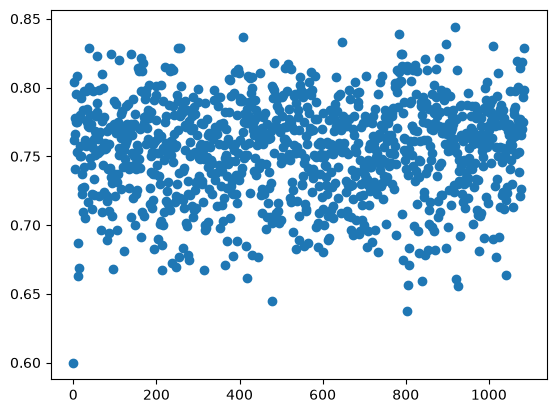

In [24]:
plt.plot(eta_array, "o")
plt.show()

### Plotting POVMs against k 

In [25]:
def get_PVM(d):
    return [get_Eij(i, i, d) for i in range(d)]

In [26]:
def POVM_against_k(meas, k_max):
    k_array = np.arange(1, k_max+1)
    
    eta_array = np.empty(k_max)
    t_array = np.empty(k_max)
    
    for i, k in enumerate(k_array):
        SDP = get_extensionSDP(meas, k)
        start_time = time.time()
        SDP.solve(solver="mosek", verbosity=0)
        end_time = time.time()
            
        
        eta = SDP.get_variable("eta").value 
        t = end_time - start_time
    
        eta_array[i] = eta
        t_array[i] = t
    
        print(f"{i+1}/{k_max}")
    return eta_array, t_array

In [27]:
d = 2
k_max = 40
k_array = np.arange(1, k_max+1)

#there is also data for d = 3, k_max = 10 precalculated but no miracle data for that one

In [28]:
#generate PVM data
if False:
    meas = get_PVM(d)
    eta_array, t_array = POVM_against_k(meas, k_max)
    
    #save PVM data
    path = NOTEBOOK_PATH + "/data/highdim_PVMs/"
    
    np.save(path + f"eta_array_(d={d}, kmax={k_max})", eta_array)
    np.save(path + f"t_array_(d={d}, kmax={k_max})", t_array)

In [29]:
#load PVM data
path = NOTEBOOK_PATH + "/data/highdim_PVMs/"

eta_array = np.load(path + f"eta_array_(d={d}, kmax={k_max})" + ".npy")
t_array = np.load(path + f"t_array_(d={d}, kmax={k_max})" + ".npy")

In [30]:
#generate miracle data
if False:
    miracle_index = 1
    
    #plot POVM
    miracle_POVM = POVMs[miracle_index]
    eta_array_miracle, t_array_miracle = POVM_against_k(miracle_POVM, k_max)

    #save miracle POVM
    date = datetime.datetime.now().strftime("%m-%d_%H-%M-%S") + "_"
    path = NOTEBOOK_PATH + "/data/highdim_PVMs/"
    
    np.save(path + date + f"eta_array_miracle_(d={d}, kmax={k_max})", eta_array_miracle)
    np.save(path + date + f"t_array_miracle_(d={d}, kmax={k_max})", t_array_miracle)
    np.save(path + date + f"miracle_POVM_(d={d}, kmax={k_max})", miracle_POVM)

In [31]:
#load miracle POVM
date = "09-28_11-59-00" + "_"
path = NOTEBOOK_PATH + "/data/highdim_PVMs/"

eta_array_miracle = np.load(path + date + f"eta_array_miracle_(d={d}, kmax={k_max})" + ".npy")
t_array_miracle = np.load(path + date + f"t_array_miracle_(d={d}, kmax={k_max})" + ".npy")
miracle_POVM = np.load(path + date + f"miracle_POVM_(d={d}, kmax={k_max})" + ".npy")

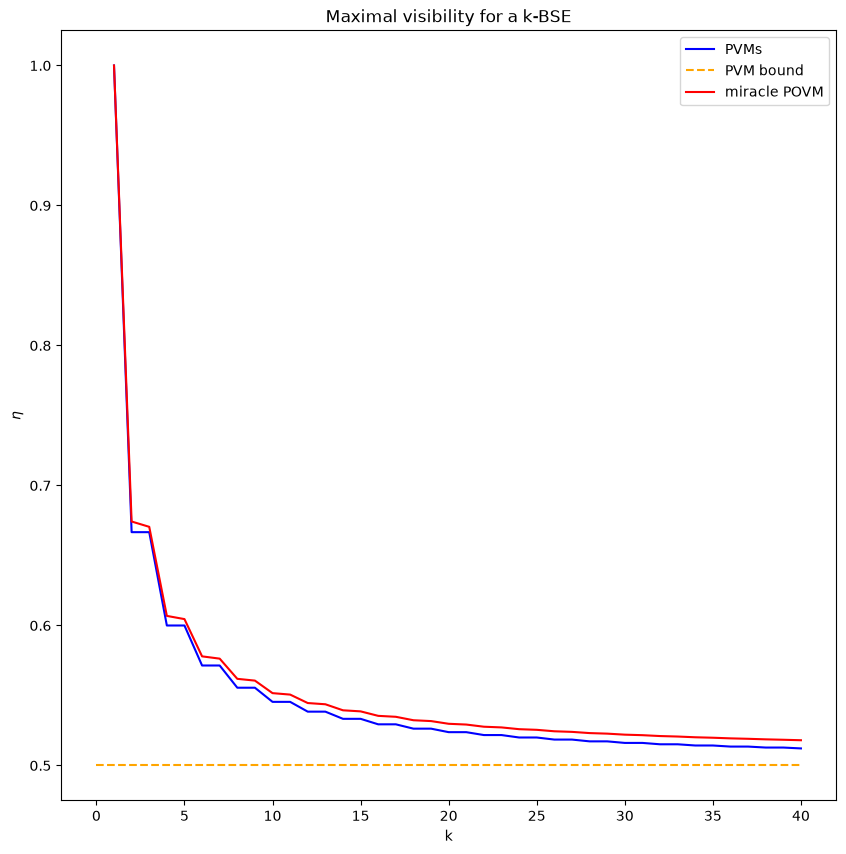

In [32]:
#plot
fig, ax = plt.subplots(figsize= (10, 10))

#PVMs
ax.plot(k_array, eta_array, label = "PVMs", color = "b")


#PVM bound
H = sum([1/i for i in np.arange(1, d+1)])
PVM_bound = (H-1) / (d-1)

ax.hlines(PVM_bound, 0, k_max, linestyles = "--", label = "PVM bound", color = "orange")


#plot miracle POVM
ax.plot(k_array, eta_array_miracle, label = "miracle POVM", color = "r")



#plot settings
ax.set_xlabel("k")
ax.set_ylabel(r"$\eta$")

ax.set_title("Maximal visibility for a k-BSE")
ax.legend()

plt.show()

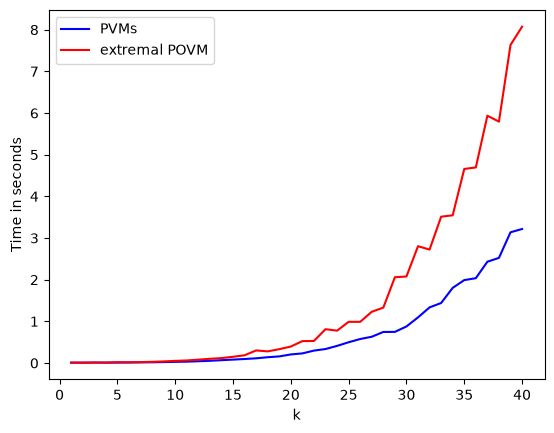

In [33]:
#time complexity
fig, ax = plt.subplots()
ax.plot(k_array, t_array, color = "b", label = "PVMs")
ax.plot(k_array, t_array_miracle, color = "r", label = "extremal POVM")

ax.legend()
ax.set_xlabel("k")
ax.set_ylabel("Time in seconds")
plt.show()

# Analysis data / Pretty plots

## Qubits

In [34]:
#load data
#3 outcome POVMs

d = 2
k = 25
samples = 900 #number of random non-extremal POVMs that are then decomposed into extremals
oDim = 3  #number of outcomes of the non-extremal POVMs

date = "09-28_12-26-16" + "_"
path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array_3outc = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array_3outc = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs_3outc = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]

#4 outcome POVMs
d = 2
k = 25
samples = 20 #number of random non-extremal POVMs that are then decomposed into extremals
oDim = 30  #number of outcomes of the non-extremal POVMs

date = "09-28_12-55-54" + "_"
path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array_4outc = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array_4outc = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs_4outc = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]



### Bar Plot

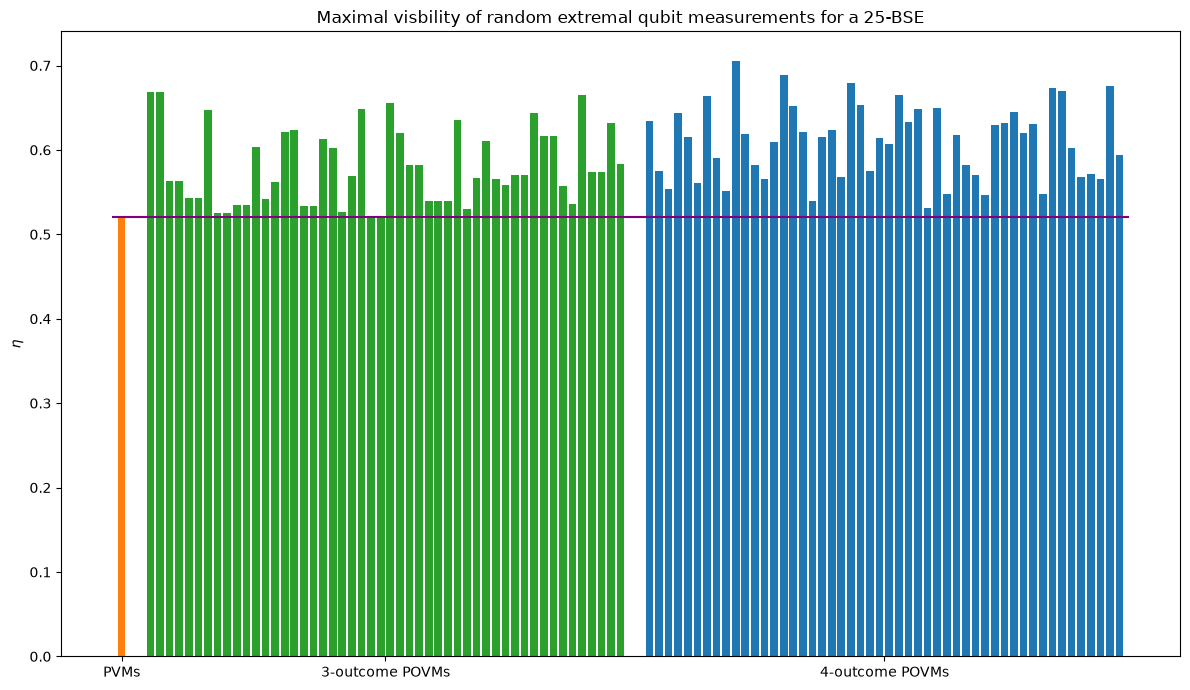

In [35]:
#number of 3 and 4 outcome POVMs shown in the plot 
n_plot_POVMs = 50
eta_plot_PVM = eta_array_3outc[0]
eta_plot_3outc = eta_array_3outc[1:(n_plot_POVMs+1)]
eta_plot_4outc = eta_array_4outc[1:(n_plot_POVMs+1)]


gap = 2  # empty space between groups

x_PVM = np.array([0])
x_3 = np.arange(n_plot_POVMs) + x_PVM[-1] + 1 + gap
x_4 = np.arange(n_plot_POVMs) + x_3[-1] + 1 + gap

fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(x_PVM, [eta_plot_PVM], color="tab:orange")
ax.bar(x_3, eta_plot_3outc, color="tab:green")
ax.bar(x_4, eta_plot_4outc, color="tab:blue")

# One tick per group, centered under each group
ax.set_xticks([x_PVM.mean(), x_3.mean(), x_4.mean()])
ax.set_xticklabels(["PVMs", "3-outcome POVMs", "4-outcome POVMs"])
ax.set_ylabel(r"$\eta$")

ax.hlines(eta_plot_PVM, -1, x_4[-1] + 1, color = "purple")

plt.title(f"Maximal visbility of random extremal qubit measurements for a {k}-BSE")
plt.tight_layout()


plt.show()

### Scatter plot

In [36]:
def partitions(items, d):
    """
    Helper function for coarse_grain_into_doutc.
    Calculates every possible way to group a set of items into d groups.
    """
    items = list(items)
    n = len(items)

    def rec(i, groups):
        if i == n:
            if len(groups) == d:
                yield [g[:] for g in groups]
            return
        if len(groups) + (n - i) < d:   # not enough elements left to reach d groups
            return
        for g in groups:                # put items[i] into an existing group
            g.append(items[i])
            yield from rec(i + 1, groups)
            g.pop()
        if len(groups) < d:             # or start a new group
            groups.append([items[i]])
            yield from rec(i + 1, groups)
            groups.pop()

    yield from rec(0, [])


def coarse_grain_into_doutc(povm):
    """
    All ways of coarse graining a POVM into a d-outcome POVM.

    Parameters
    ----------
    povm : list of np.ndarray
        The POVM effects E_0, ..., E_{n-1}.
    Returns
    -------
    coarse_povms : list of [np.ndarray, np.ndarray]
        List of d-outcome POVMs
    """
    n_effects = len(povm)
    d = np.shape(povm[0])[0]

    #nothing to coarse grain if the povm already has d outcomes 
    if n_effects == d:
        return [povm]

    indices = range(0, n_effects)
    coarse_povms = []

    coarse_graining_indices = partitions(indices, d)

    for p in coarse_graining_indices:  
        cur_povm = []
        for effect_indices in p:
            e = np.zeros((d,d), dtype = complex)
            for i in effect_indices:
                e += povm[i]
            cur_povm.append(e)
        coarse_povms.append(np.array(cur_povm))
    return  coarse_povms

def projectiveness(povm):
    """
    Calculates the projectiveness deterministically. This function is not used anymore in the notebook
    since the stochastic method is acurate enough and outperfoms this one in speed. 
    """
    assert(is_measurement(povm))
    d = (povm[0].shape)[0]
    assert d < 4, "Maximizing over all coarse grainings is not feasable for d >= 4. Use projectiveness_stochastic instead"

    
    coarse_povms = coarse_grain_into_doutc(povm)
    pness_max = 0
    for p in coarse_povms:
        pness = 0
        for e in p:
            eigval, eigvec = np.linalg.eig(e)
            lam_max = np.max(eigval.real)
            pness += lam_max
        if pness > pness_max:
            pness_max = pness

    return (pness_max-1)/(d-1)
    
def projectiveness_stochastic(povm, n_starts=50, max_iter=500, tol=1e-12, seed=None):
    """Normalized method-A measure (A - 1)/(d - 1), in [0, 1], where
        A = max over unit vectors v_1..v_d of sum_x max_i <v_i|E_x|v_i>
          = max over coarse-grainings of sum_i lambda_max(F_i).
    Computed by alternating "assign each effect to its best vector" and
    "set v_i to the top eigenvector of its block", with multistart.
    The result is a lower bound on the global maximum.
    """
    assert(is_measurement(povm))
    E = np.asarray(povm, dtype=complex)
    n, d, _ = E.shape
    rng = np.random.default_rng(seed)

    best = 0.0
    for _ in range(n_starts):
        V = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d))
        V /= np.linalg.norm(V, axis=0)
        f_old = -np.inf
        for _ in range(max_iter):
            M = np.einsum('ai,xab,bi->xi', V.conj(), E, V).real   # <v_i|E_x|v_i> - Matrix
            g = M.argmax(axis=1) #g[x] is the index of the vector |v_g[x]> that E_x overlaps the most with
            f = M.max(axis=1).sum() #for the current set of vectors, f is the objective value
            if f - f_old < tol:
                break #break if we already converged
            f_old = f
            for i in range(d):
                mask = (g == i)
                if mask.any():                  # keep old v_i if the block is empty
                    V[:, i] = np.linalg.eigh(E[mask].sum(axis=0))[1][:, -1]
        best = max(best, f)
    return (best - 1) / (d - 1)

In [37]:
#calculate the projectiveness of the POVMs
if False:
    POVM_ranking = projectiveness_stochastic #one might to test different rankings of PVMness

    #3outcome
    POVMs_3outc_ranks = np.array([POVM_ranking(p) for p in POVMs_3outc])

    #4outcome
    POVMs_4outc_ranks = np.array([POVM_ranking(p) for p in POVMs_4outc])

    #save data
    
    path = NOTEBOOK_PATH + "/data/scatter_plots/qubits/"

    #3outcome
    np.save(path + "POVMs_3outc_ranks", POVMs_3outc_ranks)
    
    #4outcome
    np.save(path + "POVMs_4outc_ranks", POVMs_4outc_ranks)

In [38]:
#load data
path = NOTEBOOK_PATH + "/data/scatter_plots/qubits/"
POVMs_3outc_ranks = np.load(path + "POVMs_3outc_ranks" + ".npy")
POVMs_4outc_ranks = np.load(path + "POVMs_4outc_ranks" + ".npy")

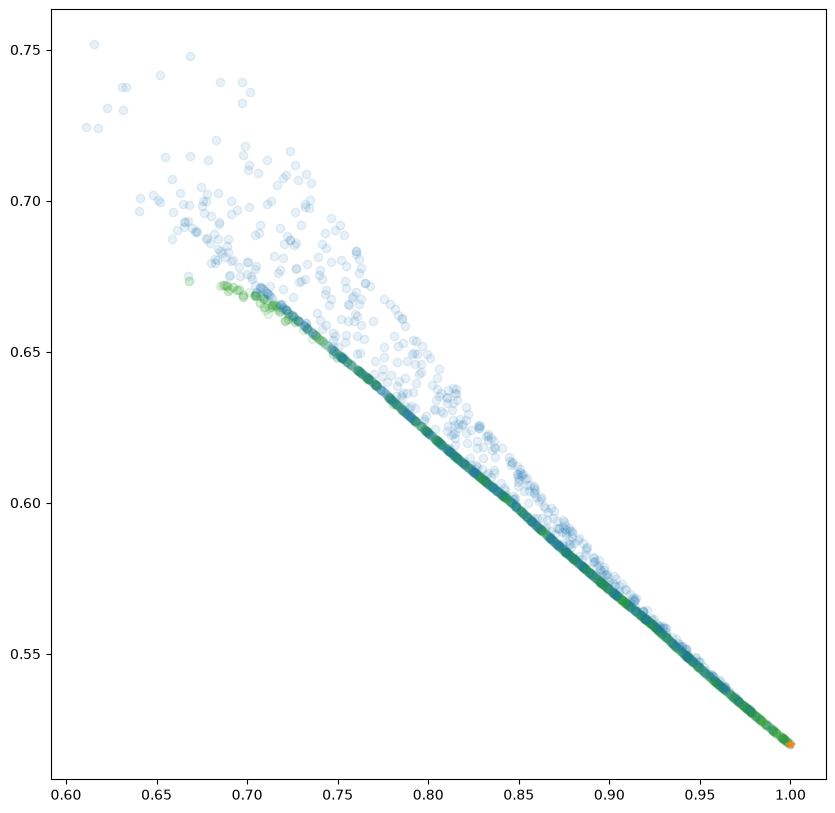

In [39]:
#both together: 
fig, ax = plt.subplots(figsize = (10,10))

ax.plot(POVMs_4outc_ranks[0], eta_array_4outc[0], "*", color = "tab:orange")
ax.scatter(POVMs_3outc_ranks, eta_array_3outc, color = "tab:green", alpha = 0.1)
ax.scatter(POVMs_4outc_ranks, eta_array_4outc, color = "tab:blue", alpha = 0.1)
plt.show()


### Scatter plot for multiple k

In [40]:
# lets if the line gets "thinner" if k increases

#load data the data we already have

#3 outcome POVMs

d = 2
k = 25
samples = 900 #number of random non-extremal POVMs that are then decomposed into extremals
oDim = 3  #number of outcomes of the non-extremal POVMs

date = "09-28_12-26-16" + "_"
path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array_3outc = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array_3outc = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs_3outc = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]

#4 outcome POVMs
d = 2
k = 25
samples = 20 #number of random non-extremal POVMs that are then decomposed into extremals
oDim = 30  #number of outcomes of the non-extremal POVMs

date = "09-28_12-55-54" + "_"
path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array_4outc = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array_4outc = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs_4outc = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]

In [41]:
#now generate more eta_array for different k but the same POVMs
if False:
    k_array = np.array([2, 5, 10, 15, 20])
    n_k = len(k_array)
    
    #3outcome
    n_POVMs_3outc = len(POVMs_3outc)
    """
    visibilies and computation times are stored in matrices of the form:
    
    K=   POVM1 POVM2 .... POVMlast
    2
    5
    10
    15
    20
    """
    eta_matrix_3outc = np.empty((n_k, n_POVMs_3outc))  
    t_matrix_3outc = np.empty((n_k, n_POVMs_3outc))
    
    print("##### Start of 3 outcome POVMs")
    for k_index, k in enumerate(k_array):
        
        print(f"k = {k}")
        for povm_index, povm in enumerate(POVMs_3outc):
        
            
            SDP = get_extensionSDP(povm, k)
            start_time = time.time()
            SDP.solve(solver="mosek", verbosity=0)
            end_time = time.time()
                
            
            eta = SDP.get_variable("eta").value 
            t = end_time - start_time
            eta_matrix_3outc[k_index][povm_index] = eta
            t_matrix_3outc[k_index][povm_index] = t            
    
    #4outcome
    n_POVMs_4outc = len(POVMs_4outc)
    
    eta_matrix_4outc = np.empty((n_k, n_POVMs_4outc))  
    t_matrix_4outc = np.empty((n_k, n_POVMs_4outc))
    
    print("##### Start of 4 outcome POVMs")
    for k_index, k in enumerate(k_array):
        
        print(f"_____k = {k}________")
        for povm_index, povm in enumerate(POVMs_4outc):
        
            #find maximal visibility
            SDP = get_extensionSDP(povm, k)
            start_time = time.time()
            SDP.solve(solver="mosek", verbosity=0)
            end_time = time.time()
                
            
            eta = SDP.get_variable("eta").value 
            t = end_time - start_time
            eta_matrix_4outc[k_index][povm_index] = eta
            t_matrix_4outc[k_index][povm_index] = t

    
    #save data
    path = NOTEBOOK_PATH + "/data/scatter_plots/qubits/"
    
    #save k-array
    np.save(path + f"k_array_(len = {len(k_array)})", k_array)
    
    #3outcome
    np.save(path + "eta_matrix_3outc", eta_matrix_3outc)
    np.save(path + "t_matrix_3outc", t_matrix_3outc)
    
    #4outcome
    np.save(path + "eta_matrix_4outc", eta_matrix_4outc)
    np.save(path + "t_matrix_4outc", t_matrix_4outc)


In [42]:
#load data
path = NOTEBOOK_PATH + "/data/scatter_plots/qubits/"
#3outcome
eta_matrix_3outc = np.load(path + "eta_matrix_3outc" + ".npy")
t_matrix_3outc = np.load(path + "t_matrix_3outc" + ".npy")

#4outcome
eta_matrix_4outc = np.load(path + "eta_matrix_4outc" + ".npy")
t_matrix_4outc = np.load(path + "t_matrix_4outc" + ".npy")

#k_array 
k_len = 5
k_array = np.load(path + f"k_array_(len = {k_len})" + ".npy")

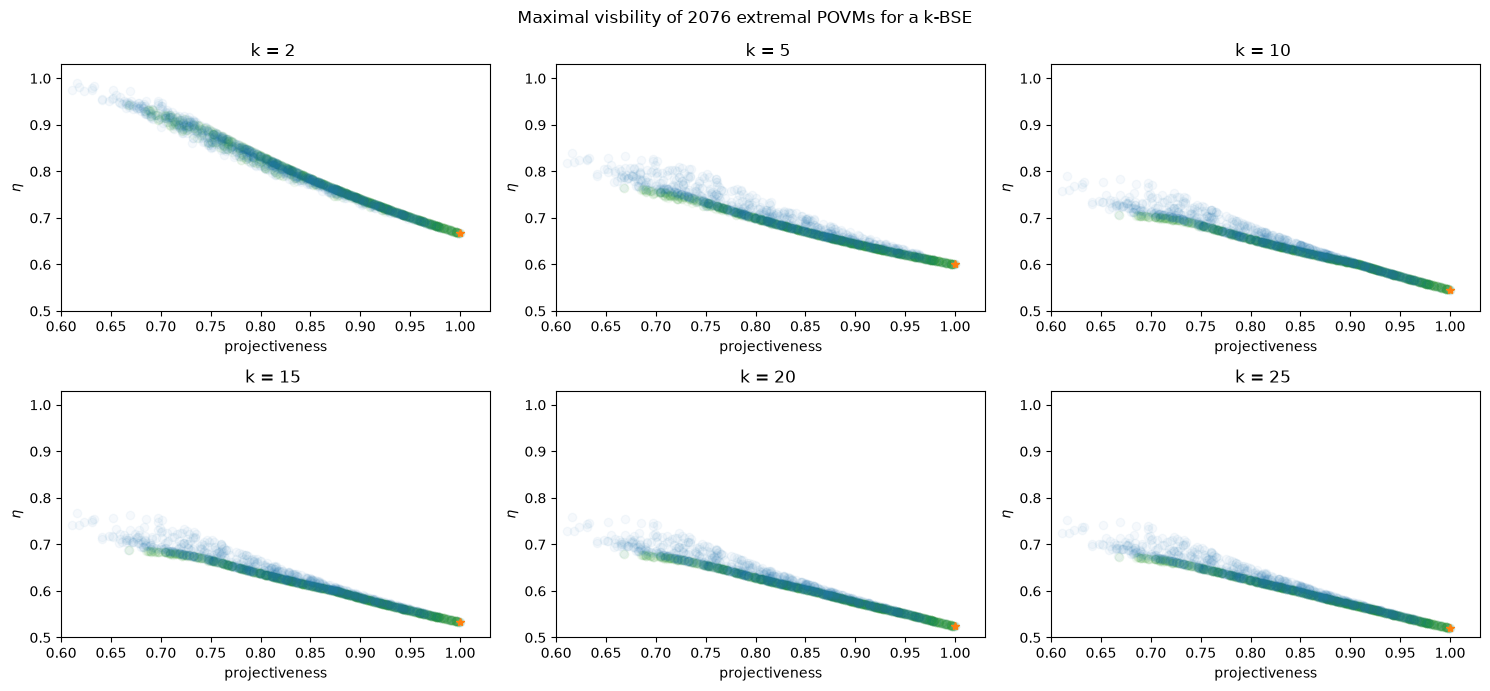

In [43]:
#both together: 

nrow = 2 
ncol = 3
fig, axs = plt.subplots(nrows=nrow, ncols=ncol, figsize = (15, 7))
axs = axs.reshape(-1)

#add the calculation we did earlier
eta_matrix_3outc = np.vstack((eta_matrix_3outc, eta_array_3outc))
t_matrix_3outc = np.vstack((t_matrix_3outc, t_array_3outc))

eta_matrix_4outc = np.vstack((eta_matrix_4outc, eta_array_4outc))
t_matrix_4outc = np.vstack((t_matrix_4outc, t_array_4outc))

k_array = np.array([2, 5, 10, 15, 20, 25]) #added the 25


#plot the new data
for k_index, k in enumerate(k_array): 
    cur_ax = axs[k_index]
    
    cur_ax.plot(POVMs_4outc_ranks[0], eta_matrix_4outc[k_index][0], "*", color = "tab:orange")
    cur_ax.scatter(POVMs_3outc_ranks, eta_matrix_3outc[k_index], color = "tab:green", alpha = 0.04)
    cur_ax.scatter(POVMs_4outc_ranks, eta_matrix_4outc[k_index], color = "tab:blue", alpha = 0.04)

    cur_ax.set_title(f"k = {k} ")
    cur_ax.set_xlabel("projectiveness")
    cur_ax.set_ylabel(r"$\eta$")
    
    cur_ax.set_xlim(0.6, 1.03)
    cur_ax.set_ylim(0.5, 1.03)



#figure options
fig.suptitle(f"Maximal visbility of {len(POVMs_3outc) + len(POVMs_4outc) - 1} extremal POVMs for a k-BSE") #-1 because theres a PVM in each set
fig.tight_layout()
plt.show()


## Qutrits

In [44]:
#load data
d = 3
k = 8
samples = 4
oDim = 25
date = "10-05_13-15-13" + "_"

path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]

n_POVMs = len(POVMs)
index_proj = [len(povm) == d for povm in POVMs]
n_proj = np.sum(index_proj)
print(f"{n_POVMs} extremal POVMs were loaded of which {n_proj} are projective.")

230 extremal POVMs were loaded of which 1 are projective.


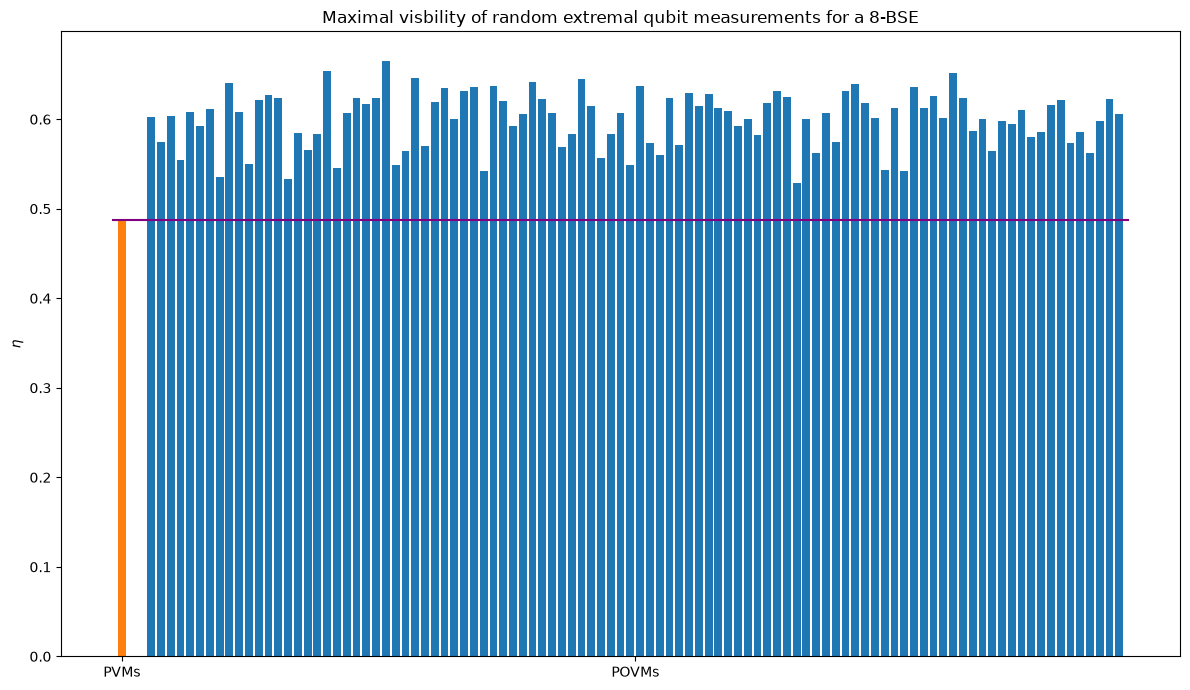

In [45]:
n_plot_POVMs = 100
eta_plot_PVM = eta_array[0]
eta_plot_POVM = eta_array[1:(n_plot_POVMs+1)]


gap = 2  # empty space between groups

x_PVM = np.array([0])
x_POVM = np.arange(n_plot_POVMs) + x_PVM[-1] + 1 + gap

fig, ax = plt.subplots(figsize=(12, 7))
ax.bar(x_PVM, [eta_plot_PVM], color="tab:orange")
ax.bar(x_POVM, eta_plot_POVM, color="tab:blue")

# One tick per group, centered under each group
ax.set_xticks([x_PVM.mean(), x_POVM.mean()])
ax.set_xticklabels(["PVMs", "POVMs"])
ax.set_ylabel(r"$\eta$")

ax.hlines(eta_plot_PVM, -1, x_POVM[-1] + 1, color = "purple")

plt.title(f"Maximal visbility of random extremal qubit measurements for a {k}-BSE")
plt.tight_layout()


plt.show()

In [46]:
#calculate the projectiveness of the POVMs
if True:
    POVM_ranking = projectiveness_stochastic #one might to test different rankings of PVMness

    #3outcome
    POVMs_ranks = np.array([POVM_ranking(p) for p in POVMs])

    #save data
    path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/"
    np.save(path + "POVMs_ranks", POVMs_ranks)

In [47]:
#load data
path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/"
POVMs_ranks = np.load(path + "POVMs_ranks" + ".npy")

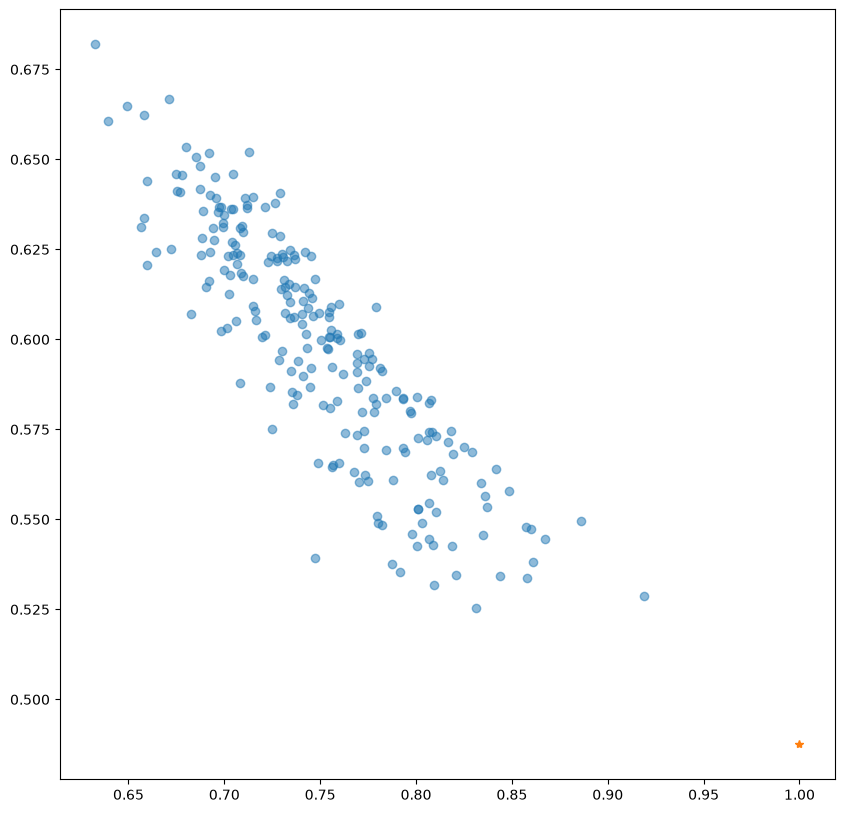

In [48]:
#plot
fig, ax = plt.subplots(figsize = (10,10))

ax.plot(POVMs_ranks[0], eta_array[0], "*", color = "tab:orange")
ax.scatter(POVMs_ranks[1:], eta_array[1:], color = "tab:blue", alpha = 0.5)
plt.show()


In [49]:
#now generate more eta_array for different k but the same POVMs
if False:
    k_array = np.array([3, 4, 5, 6, 7])
    n_k = len(k_array)           
    
    #4outcome
    n_POVMs = len(POVMs)
    
    eta_matrix = np.empty((n_k, n_POVMs))  
    t_matrix = np.empty((n_k, n_POVMs))
    
    for k_index, k in enumerate(k_array):
        
        print(f"______k = {k}______")
        for povm_index, povm in enumerate(POVMs):
        
            #find maximal visibility
            SDP = get_extensionSDP(povm, k)
            start_time = time.time()
            SDP.solve(solver="mosek", verbosity=0)
            end_time = time.time()
                
            
            eta = SDP.get_variable("eta").value 
            t = end_time - start_time
            eta_matrix[k_index][povm_index] = eta
            t_matrix[k_index][povm_index] = t
            print(f"{povm_index} / {n_POVMs}")

    
    #save data
    path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/"
    
    #save k-array
    np.save(path + f"k_array_(len = {len(k_array)})", k_array)
    
    #4outcome
    np.save(path + "eta_matrix", eta_matrix)
    np.save(path + "t_matrix", t_matrix)

To find candidates that are more incompatible than PVMs it might a good idea to only consider k = 2 and sample size of random POVMs.

In [87]:
#load data
d = 3
k = 2
samples = 52
oDim = 15
date = "10-06_10-04-38" + "_"

path = NOTEBOOK_PATH + "/data/random_extremals/"

eta_array_k2 = np.load(path + date + f"eta_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})" + ".npy")
t_array_k2 = np.load(path + date + f"t_array_(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

POVMs_padded = np.load(path + date + f"POVMs_padded(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")
outcomes_list = np.load(path + date + f"outcomes_list(d={d}, k={k}, samples = {samples}, oDim = {oDim})"+ ".npy")

#undo the padding
POVMs = [POVMs_padded[i, :outcomes_list[i]] for i in range(len(outcomes_list))]

n_POVMs = len(POVMs)
index_proj = [len(povm) == d for povm in POVMs]
n_proj = np.sum(index_proj)
print(f"{n_POVMs} extremal POVMs were loaded of which {n_proj} are projective.")

1512 extremal POVMs were loaded of which 1 are projective.


In [88]:
#calculate the projectiveness of the POVMs
if False:
    POVM_ranking = projectiveness_stochastic #one might to test different rankings of PVMness

    POVMs_ranks = np.array([POVM_ranking(p) for p in POVMs])

    #save data
    path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/"
    np.save(path + "POVMs_ranks_k2", POVMs_ranks)

In [89]:
#load data
path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/"
POVMs_ranks_k2 = np.load(path + "POVMs_ranks_k2" + ".npy")

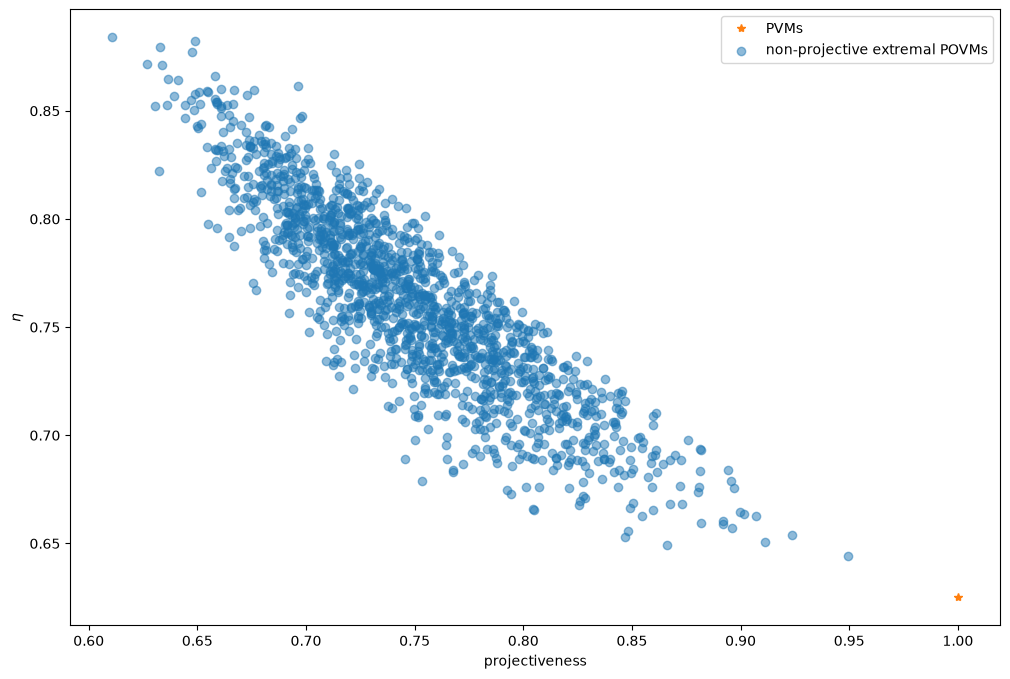

In [90]:
#plot
fig, ax = plt.subplots(figsize = (12, 8))

ax.plot(POVMs_ranks_k2[0], eta_array_k2[0], "*", color = "tab:orange", label = "PVMs")
ax.scatter(POVMs_ranks_k2[1:], eta_array_k2[1:], color = "tab:blue", alpha = 0.5, label = "non-projective extremal POVMs")

ax.set_xlabel("projectiveness")
ax.set_ylabel(r"$\eta$")

ax.legend()
plt.show()

Plot "best" 10 against k and see if one might overtake PVM.

In [104]:
indices_bestPOVMs = np.argsort(eta_array)[:11] #first one will always be 0 corresponding to PVM
bestPOVMs = []
eta_best10_k2 = np.empty(11)

for j, i in enumerate(indices_bestPOVMs):
    bestPOVMs.append(POVMs[i])
    eta_best10_k2[j] = eta_array_k2[i]

In [105]:
#now generate more eta_array for different k but the same POVMs
if False:
    k_array = np.arange(3, 9)
    n_k = len(k_array)
    
    #3outcome
    n_POVMs = len(bestPOVMs)
    """
    visibilies and computation times are stored in matrices of the form:
    
        PVM POVM1 POVM2 .... POVM10
    k=3
    4
    5
    6
    7
    8
    """
    eta_matrix_best10 = np.empty((n_k, n_POVMs))  
    t_matrix_best10 = np.empty((n_k, n_POVMs))
    
    for k_index, k in enumerate(k_array):
        
        print(f"k = {k}")
        for povm_index, povm in enumerate(bestPOVMs):
        
            
            SDP = get_extensionSDP(povm, k)
            start_time = time.time()
            SDP.solve(solver="mosek", verbosity=0)
            end_time = time.time()
                
            
            eta = SDP.get_variable("eta").value 
            t = end_time - start_time
            eta_matrix_best10[k_index][povm_index] = eta
            t_matrix_best10[k_index][povm_index] = t   
            print(f"{povm_index+1} / {n_POVMs}")
            
    #save data
    path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/"
    
    #save k-array
    np.save(path + f"k_array_(len = {len(k_array)})", k_array)
    
    #3outcome
    np.save(path + "eta_matrix_best10", eta_matrix_best10)
    np.save(path + "t_matrix_best10", t_matrix_best10)

In [116]:
#load data
path = NOTEBOOK_PATH + "/data/scatter_plots/qutrits/" 
eta_matrix_best10 = np.load(path + "eta_matrix_best10" + ".npy")
t_matrix_best10 = np.load(path + "t_matrix_best10" + ".npy")

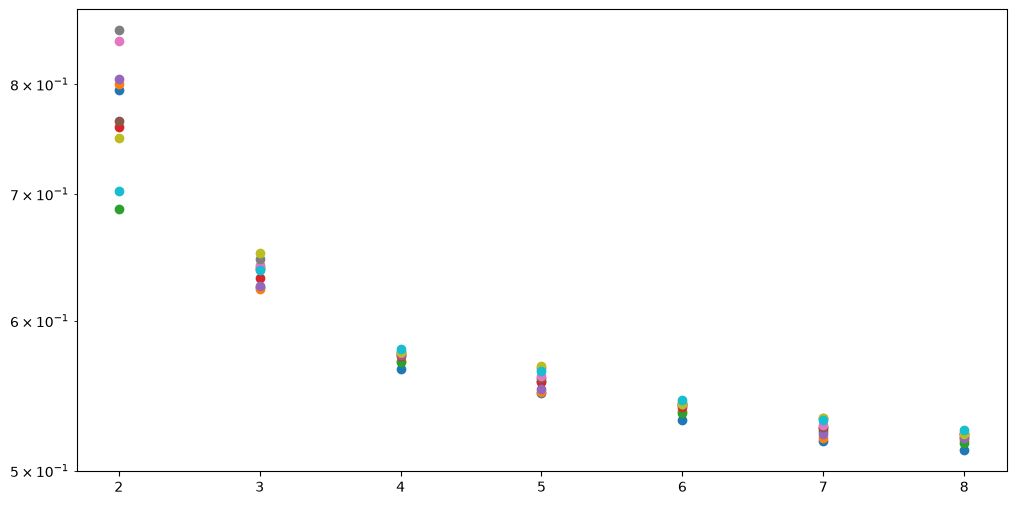

In [121]:
fig, ax = plt.subplots(figsize = (12, 6))


#add the values for k = 2 we already had
eta_matrix_best10_plot = np.vstack((eta_best10_k2, eta_matrix_best10))
k_array = np.arange(2, 9)

for i in range(len(bestPOVMs[1:])):
    ax.semilogy(k_array, eta_matrix_best10_plot[:, i+1], "o")

plt.show()

In [79]:
b = np.arange(1, 10)
print(b)
print(b[1:])

[1 2 3 4 5 6 7 8 9]
[2 3 4 5 6 7 8 9]
